# BeautifulSoup

Beautiful Soup is a python package that parses the unwanted data and helps to organize and format the messy web data by fixing bad HTML and present to us in an easily-traversable XML structures.

## HTML Tree Struture

```
<html>
   <head>
      <title>TutorialsPoint</title>
   </head>
   <body>
      <h1>Tutorialspoint Online Library</h1>
      <p><b>It's all Free</b></p>
   </body>
</html>
```

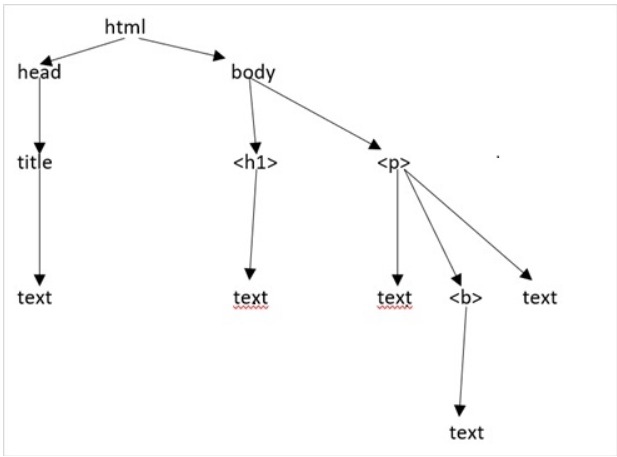

In [22]:
file = open("page.html", "rt")
html_page = file.read()

## Parsing the HTML with Beautiful Soup

In [21]:
from bs4 import BeautifulSoup

BeautifulSoup() constructor takes HTML content and a string specifying the parser and returns us an object which allows us to extract info. from HTML content.<br> 
Here "html.parser" tells Beautiful Soup to use the built-in HTML parser.

In [82]:
soup = BeautifulSoup(html_page, "html.parser")

In [84]:
# Prettify the entire document
print(soup.prettify())

<html class="no-js" lang="en-us">
 <!--<![endif]-->
 <head>
  <title>
   All products | Books to Scrape - Sandbox
  </title>
  <meta content="text/html; charset=utf-8" http-equiv="content-type"/>
  <meta content="24th Jun 2016 09:29" name="created"/>
  <meta content="" name="description"/>
  <meta content="width=device-width" name="viewport"/>
  <meta content="NOARCHIVE,NOCACHE" name="robots"/>
  <!-- Le HTML5 shim, for IE6-8 support of HTML elements -->
  <!--[if lt IE 9]>
        <script src="//html5shim.googlecode.com/svn/trunk/html5.js"></script>
        <![endif]-->
  <link href="static/oscar/favicon.ico" rel="shortcut icon"/>
  <link href="static/oscar/css/styles.css" rel="stylesheet" type="text/css"/>
  <link href="static/oscar/js/bootstrap-datetimepicker/bootstrap-datetimepicker.css" rel="stylesheet"/>
  <link href="static/oscar/css/datetimepicker.css" rel="stylesheet" type="text/css"/>
 </head>
 <body class="default" id="default">
  <header class="header container-fluid">
   <

### List of some important parsers:
* html.parser
* lxml
* html5lib

### Extracting data by Targeting DOM elements

#### Simple Tags

In [37]:
# title tag of the page
soup.title

<title>
    All products | Books to Scrape - Sandbox
</title>

In [54]:
# entire body of the page
soup.body.text[:20]

'\n\n\n\nBooks to Scrape '

### Important Properties

#### Name

In [56]:
# fetching  name of the tag
soup.p.name

'p'

In [61]:
# changing the tag name
soup_test = BeautifulSoup('<b class="boldest">TutorialsPoint</b>', 'html.parser')
tag = soup_test.b
tag.name = "strong"
print (tag)

<strong class="boldest">TutorialsPoint</strong>


#### Text

In [119]:
# Text tag is used to fetch all the text content inside a particular tag (including nested tag content)
soup_test = BeautifulSoup('<div> Hello <b>Python</b> World </div>', 'html')
print (soup_test.div.text)
print (soup_test.div.get_text())

 Hello Python World 
 Hello Python World 


#### String

In [124]:
# String tag is used to fetch the text content only for the tag specified and not its nested tags
soup_test = BeautifulSoup('<div>Hello World</div>', 'html')
print (soup_test.div.string)
soup_test = BeautifulSoup('<div> Hello <b>Python</b> World </div>', 'html')
print (soup_test.div.string)
soup_test = BeautifulSoup('<div> Hello <b>Python</b> World </div>', 'html')
print (soup_test.div.b.string)

Hello World
None
Python


#### Attr

In [80]:
# fetching attributes of a tag
soup_test = BeautifulSoup('<input type="text" name="name" value="Raju">', 'html')
tag = soup_test.input
print (tag.attrs)
print (tag['value']) #This can raise error in case of no value found
print (tag.get('value')) #This returns None if no value found

{'type': 'text', 'name': 'name', 'value': 'Raju'}
Raju
Raju


In [68]:
# Updating tag value
soup_test = BeautifulSoup('<input type="text" name="name" value="Raju">', 'html')
tag = soup_test.input

print (tag.attrs)
tag['value']='Ravi'
print (soup_test)

{'type': 'text', 'name': 'name', 'value': 'Raju'}
<input name="name" type="text" value="Ravi"/>


In [70]:
# Adding/Deleting Tag
soup = BeautifulSoup('<input type="text" name="name" value="Raju">', 'html')
tag = soup.input

tag['id']='nm'
del tag['value']
print (soup)

<input id="nm" name="name" type="text"/>


#### Parent

In [127]:
div = soup.find("div")
print(div.parent)

<header class="header container-fluid">
<div class="page_inner">
<div class="row">
<div class="col-sm-8 h1"><a href="index.html">Books to Scrape</a><small> We love being scraped!</small>
</div>
</div>
</div>
</header>


#### Children

In [138]:
# Returns all the direct children of a particular element in form of iterator
div = soup.find("div")
count = 1
for i in div.children:
    print("Div: ",count,"\n", i)
    count = count + 1

Div:  1 
 

Div:  2 
 <div class="row">
<div class="col-sm-8 h1"><a href="index.html">Books to Scrape</a><small> We love being scraped!</small>
</div>
</div>
Div:  3 
 



#### Descendants

In [139]:
# Returns all the children (including nested elements) of a particular element in form of iterator
div = soup.find("div")
count = 1
for i in div.descendants:
    print("Div: ",count,"\n", i)
    count = count + 1

Div:  1 
 

Div:  2 
 <div class="row">
<div class="col-sm-8 h1"><a href="index.html">Books to Scrape</a><small> We love being scraped!</small>
</div>
</div>
Div:  3 
 

Div:  4 
 <div class="col-sm-8 h1"><a href="index.html">Books to Scrape</a><small> We love being scraped!</small>
</div>
Div:  5 
 <a href="index.html">Books to Scrape</a>
Div:  6 
 Books to Scrape
Div:  7 
 <small> We love being scraped!</small>
Div:  8 
  We love being scraped!
Div:  9 
 

Div:  10 
 

Div:  11 
 



#### Contents

In [116]:
# Returns all the direct children of a particular element in form of list
div = soup.find("div")
print(div.contents)

['\n', <div class="row">
<div class="col-sm-8 h1"><a href="index.html">Books to Scrape</a><small> We love being scraped!</small>
</div>
</div>, '\n']


#### Next Sibling

In [143]:
a = soup.find("a")
print(a.next_sibling)

<small> We love being scraped!</small>


#### Previous Sibling

In [158]:
a = soup.find("p")
print(a.previous_sibling)

### Important Functions

#### Find
This method searches the parsed HTML document from top to bottom and returns the first occurrence of the tag you specify.

In [41]:
soup.find("a")

<a href="index.html">Books to Scrape</a>

#### FindAll
This method searches the entire parsed HTML document and returns a list containing all instances of the specified tag or set of tags.

In [42]:
soup.find_all("a")

[<a href="index.html">Books to Scrape</a>,
 <a href="index.html">Home</a>,
 <a href="catalogue/category/books_1/index.html">
                             
                                 Books
                             
                         </a>,
 <a href="catalogue/category/books/travel_2/index.html">
                             
                                 Travel
                             
                         </a>,
 <a href="catalogue/category/books/mystery_3/index.html">
                             
                                 Mystery
                             
                         </a>,
 <a href="catalogue/category/books/historical-fiction_4/index.html">
                             
                                 Historical Fiction
                             
                         </a>,
 <a href="catalogue/category/books/sequential-art_5/index.html">
                             
                                 Sequential Art
            

#### Finding by Tag


In [46]:
soup.find("div")

<div class="page_inner">
<div class="row">
<div class="col-sm-8 h1"><a href="index.html">Books to Scrape</a><small> We love being scraped!</small>
</div>
</div>
</div>

#### Finding by Class

In [49]:
soup.find(class_="page_inner")

<div class="page_inner">
<div class="row">
<div class="col-sm-8 h1"><a href="index.html">Books to Scrape</a><small> We love being scraped!</small>
</div>
</div>
</div>

#### Finding by ID

In [51]:
soup.find(id="promotions_left")

<div id="promotions_left">
</div>

#### Find by Multiple Items

In [89]:
soup.find_all("img", class_="thumbnail")[:5]

[<img alt="A Light in the Attic" class="thumbnail" src="media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/>,
 <img alt="Tipping the Velvet" class="thumbnail" src="media/cache/26/0c/260c6ae16bce31c8f8c95daddd9f4a1c.jpg"/>,
 <img alt="Soumission" class="thumbnail" src="media/cache/3e/ef/3eef99c9d9adef34639f510662022830.jpg"/>,
 <img alt="Sharp Objects" class="thumbnail" src="media/cache/32/51/3251cf3a3412f53f339e42cac2134093.jpg"/>,
 <img alt="Sapiens: A Brief History of Humankind" class="thumbnail" src="media/cache/be/a5/bea5697f2534a2f86a3ef27b5a8c12a6.jpg"/>]

#### Find by Attributes

In [96]:
soup_html = BeautifulSoup(
"""
<div class="download" value="dbl"></div>
<div class="download" value="dbl"></div>
<div class="upload" value="dbl"></div>
<div class="download" value="dbl"></div>
"""
)    
for tag in soup_html.find_all("div", attrs={"class": "download","value": "dbl"}):
    print(tag)

<div class="download" value="dbl"></div>
<div class="download" value="dbl"></div>
<div class="download" value="dbl"></div>


#### Searching by Text

In [97]:
soup_html = BeautifulSoup(
"""
<div class="download" value="dbl">Book</div>
<div class="download" value="dbl">Book</div>
<div class="upload" value="dbl">PC</div>
<div class="download" value="dbl">Desktop</div>
"""
)   

for tag in soup_html.find_all("div", string = "Book"):
    print(tag)

<div class="download" value="dbl">Book</div>
<div class="download" value="dbl">Book</div>


#### Searching by Regular Expression

In [102]:
import re
soup_html = BeautifulSoup(
"""
<div class="download" value="dbl">book123@gmail.com</div>
<div class="download" value="dbl">grok123@gmail.com</div>
<div class="upload" value="dbl">Mland1@23@gmail.com</div>
<div class="download" value="dbl">book456@gmail.com</div>
"""
)  
soup_html.find_all(string=re.compile(r"^[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}$"))

['book123@gmail.com', 'grok123@gmail.com', 'book456@gmail.com']